# Handwritten Digit Recognizer (MNIST)
**Goal:** Train a convolutional neural network (CNN) to classify handwritten digits from 0 to 9.

**Dataset:** MNIST, downloaded automatically through TensorFlow/Keras.
**Evaluation:** Test accuracy, classification report, confusion matrix, and example predictions.
**Compute:** Designed to run on a CPU; a GPU can make training faster.

## 1. Install dependencies


In [2]:
%pip install -q tensorflow matplotlib scikit-learn

## 2. Import libraries

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## 3. Load the MNIST dataset

In [4]:
# Keras downloads MNIST automatically the first time this runs.
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Test images:", x_test.shape)
print("Test labels:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)


## 4. View sample images

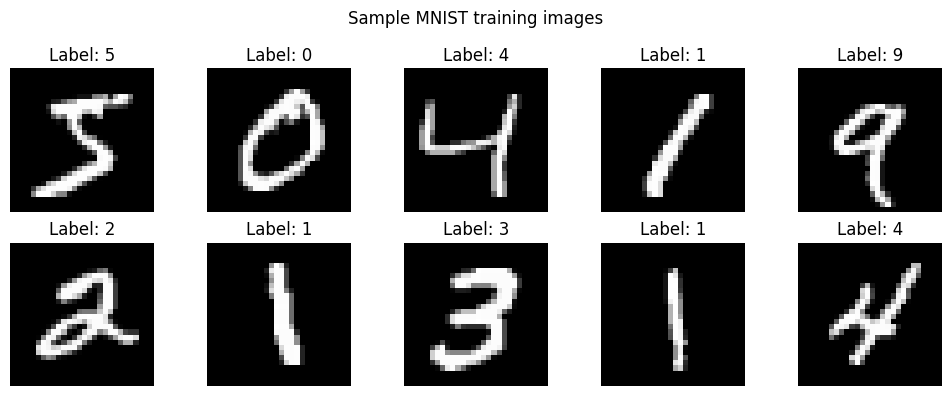

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[i], cmap="gray")
    ax.set_title(f"Label: {y_train[i]}")
    ax.axis("off")
plt.suptitle("Sample MNIST training images")
plt.tight_layout()
plt.show()

## 5. Prepare the images
Pixel values range from 0 to 255. Scale them to 0–1 and add a channel dimension because the CNN expects image tensors shaped like `(height, width, channels)`.

In [6]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train = x_train[..., np.newaxis]
x_test = x_test[..., np.newaxis]

print("CNN input shape:", x_train.shape[1:])

CNN input shape: (28, 28, 1)


## 6. Build and train a CNN
The model uses two convolution layers, max pooling, dropout, and a dense output layer with 10 classes.

In [7]:
model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, kernel_size=(3, 3), activation="relu"),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Conv2D(64, kernel_size=(3, 3), activation="relu"),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Flatten(),
    layers.Dropout(0.30),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
history = model.fit(
    x_train, y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.10,
    verbose=1
)

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 55s 127ms/step - accuracy: 0.9179 - loss: 0.2803 - val_accuracy: 0.9778 - val_loss: 0.0730
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 43s 102ms/step - accuracy: 0.9747 - loss: 0.0812 - val_accuracy: 0.9865 - val_loss: 0.0475
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 80s 98ms/step - accuracy: 0.9819 - loss: 0.0582 - val_accuracy: 0.9887 - val_loss: 0.0379
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 41s 98ms/step - accuracy: 0.9853 - loss: 0.0466 - val_accuracy: 0.9887 - val_loss: 0.0361
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 81s 95ms/step - accuracy: 0.9872 - loss: 0.0397 - val_accuracy: 0.9898 - val_loss: 0.0340


## 7. Plot training progress

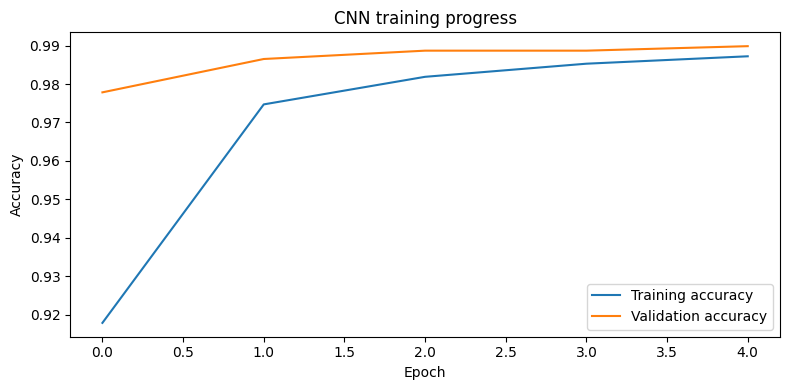

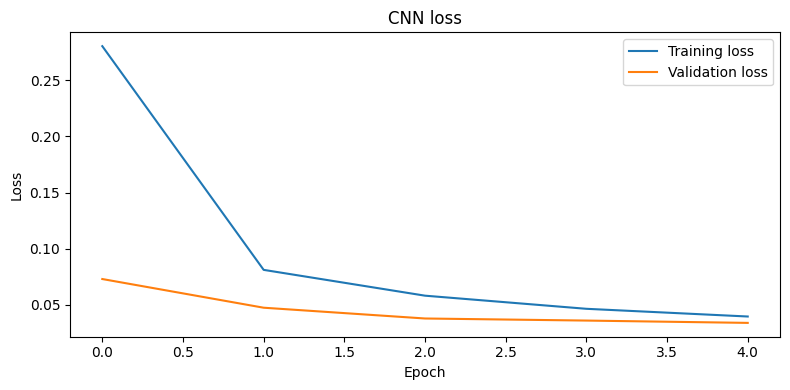

In [9]:
plt.figure(figsize=(8, 4))
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN training progress")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN loss")
plt.legend()
plt.tight_layout()
plt.show()

## 8. Evaluate on the test set

Test loss: 0.0300
Test accuracy: 99.0600%

Classification report:
              precision    recall  f1-score   support

           0     0.9969    0.9888    0.9928       980
           1     0.9895    0.9982    0.9939      1135
           2     0.9894    0.9932    0.9913      1032
           3     0.9940    0.9911    0.9926      1010
           4     0.9889    0.9969    0.9929       982
           5     0.9779    0.9944    0.9861       892
           6     0.9937    0.9854    0.9895       958
           7     0.9903    0.9883    0.9893      1028
           8     0.9918    0.9897    0.9908       974
           9     0.9930    0.9792    0.9860      1009

    accuracy                         0.9906     10000
   macro avg     0.9905    0.9905    0.9905     10000
weighted avg     0.9906    0.9906    0.9906     10000



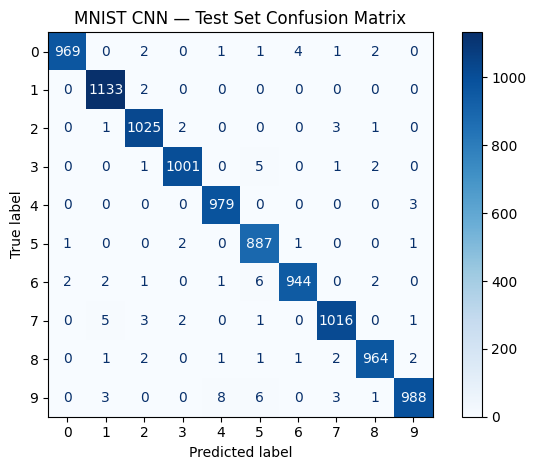

In [10]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4%}")

probabilities = model.predict(x_test, verbose=0)
y_pred = np.argmax(probabilities, axis=1)

print("\nClassification report:")
print(classification_report(y_test, y_pred, digits=4))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, cmap="Blues", values_format="d"
)
plt.title("MNIST CNN — Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

## 9. Visualize predictions

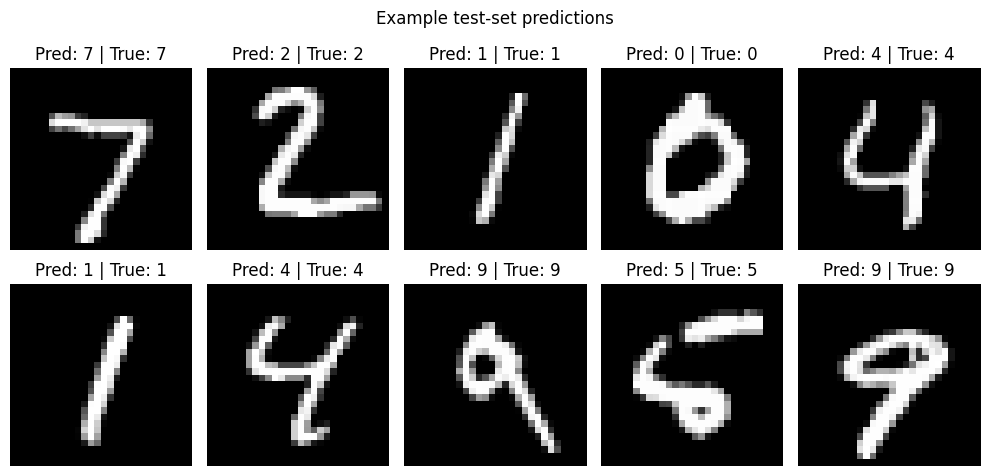

In [11]:
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for i, ax in enumerate(axes.flat):
    image_index = i
    predicted = int(y_pred[image_index])
    actual = int(y_test[image_index])
    ax.imshow(x_test[image_index].squeeze(), cmap="gray")
    ax.set_title(f"Pred: {predicted} | True: {actual}")
    ax.axis("off")
plt.suptitle("Example test-set predictions")
plt.tight_layout()
plt.show()

## 10. Predict a single test image
Change `image_index` to inspect another image. The displayed confidence is the model's probability for its selected class, not a guarantee of correctness.

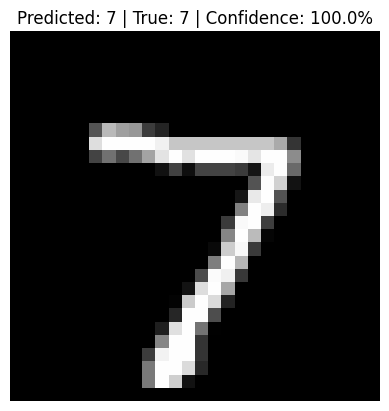

Probabilities for digits 0–9:
[0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]


In [12]:
image_index = 0
image_to_predict = x_test[image_index]
prediction_scores = model.predict(image_to_predict[np.newaxis, ...], verbose=0)[0]
predicted_digit = int(np.argmax(prediction_scores))

plt.imshow(image_to_predict.squeeze(), cmap="gray")
plt.title(
    f"Predicted: {predicted_digit} | True: {int(y_test[image_index])} | "
    f"Confidence: {prediction_scores[predicted_digit]:.1%}"
)
plt.axis("off")
plt.show()

print("Probabilities for digits 0–9:")
print(np.round(prediction_scores, 3))